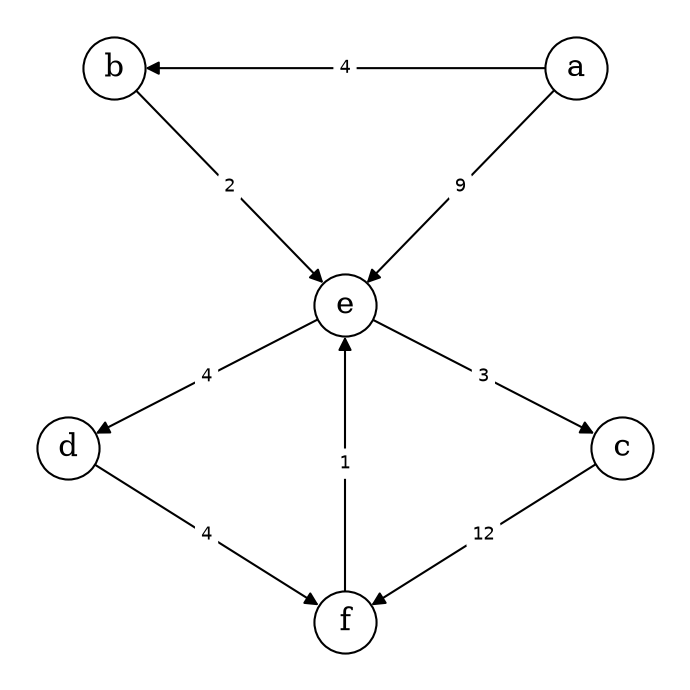

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# Створення орієнтованого графа
G = nx.DiGraph()

edges = [
    ('a', 'b', 4),
    ('a', 'e', 9),
    ('b', 'e', 2),
    ('e', 'd', 4),
    ('e', 'c', 3),
    ('d', 'f', 4),
    ('c', 'f', 12),
    ('f', 'e', 1)
]

for u, v, w in edges:
    G.add_edge(u, v, weight=w)

# Точні координати вершин для відтворення структури
pos = {
    'b': (-1.0,  1.5),
    'a': ( 1.0,  1.5),
    'e': ( 0.0,  0.0),
    'd': (-1.2, -0.9),
    'c': ( 1.2, -0.9),
    'f': ( 0.0, -2.0)
}

plt.figure(figsize=(7, 7))

# Малювання вершин
nx.draw_networkx_nodes(
    G, pos,
    node_color='white',
    edgecolors='black',
    node_size=2000,
    linewidths=1.5
)

# Підписи вершин шрифтом курсивом
nx.draw_networkx_labels(
    G, pos,
    font_size=22,
    font_family='serif',
    font_weight='normal',
    font_color='black'
)

# Малювання орієнтованих ребер (стрілок)
nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=20,
    arrowstyle='-|>',
    node_size=2000,
    edge_color='black',
    width=1.5
)

# Підписи ваг ребер
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=13,
    font_family='sans-serif',
    font_color='black',
    rotate=False
)

plt.axis('off')
plt.tight_layout()
plt.show()

In [10]:
# Список вершин та індексація
nodes = list(G.nodes)
obj = {v: i for i, v in enumerate(nodes)}
nodes_len = len(nodes)
edges_weight = dict(nx.get_edge_attributes(G, 'weight'))

# Матриця суміжності
def matrix_adj():
    matrix = [[0] * nodes_len for _ in range(nodes_len)]
    for u, v, weight in G.edges(data='weight'):
        matrix[obj[u]][obj[v]] = weight
    return matrix

matrix = matrix_adj()

# Алгоритм Дейкстри

In [11]:
import math

# Алгоритм Дейкстри
def dijkstra(start_idx):
    def get_link_v(v, D):
        for i, weight in enumerate(D[v]):
            if weight > 0:
                yield i

    def arg_min(T, S):
        amin = -1
        m = math.inf
        for i, t in enumerate(T):
            if t < m and i not in S:
                m = t
                amin = i
        return amin

    T = [math.inf] * nodes_len
    v = obj[start_idx]
    previous = [None] * nodes_len
    S = {v}
    T[v] = 0

    while v != -1:
        for j in get_link_v(v, matrix):
            if j not in S:
                w = T[v] + matrix[v][j]
                if w < T[j]:
                    T[j] = w
                    previous[j] = v
        v = arg_min(T, S)
        if v != -1:
            S.add(v)
            
    return T, previous

# Відновлення маршруту
def get_path(start, target, previous):
    if start == target:
        return [start]

    path = []
    current = obj[target]
    while current is not None:
        path.append(nodes[current])
        if current == obj[start]:
            break
        current = previous[current]

    # Якщо цикл завершився, але до початкової вершини не дійшли — шляху немає
    if not path or path[-1] != start:
        return []

    path.reverse()
    return path

# Розрахунок
start_idx = 'a'
dd, previous = dijkstra(start_idx)

In [4]:
print(f"Результати алгоритму Дейкстри для вершини [{start_idx}]:")
print("-" * 50)
print(f"{'Ціль':^6} | {'Відстань':^10} | {'Маршрут'}")
print("-" * 50)

for i, dist in enumerate(dd):
    target = nodes[i]
    if dist == math.inf:
        print(f"{target:^6} | {'∞':^10} | Немає шляху")
    else:
        path = get_path(start_idx, target, previous)
        route = " → ".join(path)
        print(f"{target:^6} | {dist:^10} | {route}")

print("-" * 50)

Результати алгоритму Дейкстри для вершини [a]:
--------------------------------------------------
 Ціль  |  Відстань  | Маршрут
--------------------------------------------------
  a    |     0      | a
  b    |     4      | a → b
  e    |     6      | a → b → e
  d    |     10     | a → b → e → d
  c    |     9      | a → b → e → c
  f    |     14     | a → b → e → d → f
--------------------------------------------------


In [5]:
print(f"\nПокрокові маршрути від вершини '{start_idx}':")
print("=" * 75)
print(f"{'Ціль':^6} | {'Відстань':^10} | {'Покроковий ланцюг переходів':<53}")
print("-" * 75)

for i, dist in enumerate(dd):
    target = nodes[i]
    if dist == math.inf:
        print(f"{target:^6} | {'∞':^10} | Шлях відсутній")
        continue

    path = get_path(start_idx, target, previous)
    
    if len(path) == 1:
        steps_str = f"[{path[0]}] (початкова точка)"
    else:
        steps = [f"{u} -({matrix[obj[u]][obj[v]]})-> {v}" for u, v in zip(path[:-1], path[1:])]
        steps_str = " ; ".join(steps)

    print(f"{target:^6} | {dist:^10} | {steps_str:<53}")

print("=" * 75)


Покрокові маршрути від вершини 'a':
 Ціль  |  Відстань  | Покроковий ланцюг переходів                          
---------------------------------------------------------------------------
  a    |     0      | [a] (початкова точка)                                
  b    |     4      | a -(4)-> b                                           
  e    |     6      | a -(4)-> b ; b -(2)-> e                              
  d    |     10     | a -(4)-> b ; b -(2)-> e ; e -(4)-> d                 
  c    |     9      | a -(4)-> b ; b -(2)-> e ; e -(3)-> c                 
  f    |     14     | a -(4)-> b ; b -(2)-> e ; e -(4)-> d ; d -(4)-> f    


# Алгоритм Флойда

In [15]:
nodes = list(G.nodes)
nodes_len = len(nodes)
obj = {v: i for i, v in enumerate(nodes)}


def matrix_adj():
  # Заповнюємо inf за замовчуванням
  matrix = [[inf] * nodes_len for _ in range(nodes_len)]

  # На головній діагоналі відстань від вершини до самої себе дорівнює 0
  for i in range(nodes_len):
    matrix[i][i] = 0

  # Заповнюємо тільки орієнтовані ребра (u -> v)
  for u, v, weight in G.edges(data="weight"):
    matrix[obj[u]][obj[v]] = weight

  return matrix

matrix=matrix_adj()

In [16]:
from math import inf

nodes_len = len(nodes)

def floyd_warshall(matrix):
    
    matrix_len = len(matrix)
    # Створюємо глибоку копію матриці, щоб не змінювати оригінал
    dist = [row[:] for row in matrix]
    previous = [[None] * matrix_len for _ in range(matrix_len)]

    for k in range(matrix_len):
        for i in range(matrix_len):
            for j in range(matrix_len):
                if dist[i][k] + dist[k][j] < dist[i][j]:
                    dist[i][j] = dist[i][k] + dist[k][j]
                    previous[i][j] = k

    return dist, previous


def get_path(start, target, previous, dist_matrix):
    if dist_matrix[start][target] == inf:
        return None

    if start == target:
        return [start]

    middle = previous[start][target]
    if middle is None:
        return [start, target]

    left = get_path(start, middle, previous, dist_matrix)
    right = get_path(middle, target, previous, dist_matrix)

    return left[:-1] + right


dist_matrix, previous = floyd_warshall(matrix)

In [17]:
from math import inf

# ANSI-коди для форматування тексту
BOLD = "\033[1m"
RESET = "\033[0m"


def print_table_matrix(matrix, nodes_list, title):
  print(f"\n{BOLD}{title}:{RESET}")

  display_data = []
  for row in matrix:
    display_data.append(
        ["∞" if val == inf else str(val) for val in row]
    )  # або 'inf'

  col_w = 6  # ширина колонки зі значеннями

  # Верхня межа
  top_border = "┌────┬" + "┬".join(["─" * col_w for _ in nodes_list]) + "┐"
  print(top_border)

  # Заголовок стовпців із ЖИРНИМИ вершинами
  header_cells = "".join([f" {BOLD}{v:^{col_w - 2}}{RESET} │" for v in nodes_list])
  print(f"│    │{header_cells}")

  # Розділювач після заголовка
  mid_border = "├────┼" + "┼".join(["─" * col_w for _ in nodes_list]) + "┤"
  print(mid_border)

  # Рядки таблиці з ЖИРНИМИ вершинами у лівому стовпці
  for i, row in enumerate(display_data):
    row_cells = "".join([f"{val:^{col_w}}│" for val in row])
    print(f"│ {BOLD}{nodes_list[i]:<2}{RESET} │{row_cells}")
    if i < len(nodes_list) - 1:
      inner_border = (
          "├────┼" + "┼".join(["─" * col_w for _ in nodes_list]) + "┤"
      )
      print(inner_border)

  # Нижня межа
  bottom_border = "└────┴" + "┴".join(["─" * col_w for _ in nodes_list]) + "┘"
  print(bottom_border)


# 1. Початкова матриця суміжності до алгоритму
print_table_matrix(
    matrix, nodes, "Матриця суміжності (ваг ребер) до алгоритму"
)


Матриця суміжності (ваг ребер) до алгоритму:
┌────┬──────┬──────┬──────┬──────┬──────┬──────┐
│    │  a   │  b   │  e   │  d   │  c   │  f   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ a  │  0   │  4   │  9   │  ∞   │  ∞   │  ∞   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ b  │  ∞   │  0   │  2   │  ∞   │  ∞   │  ∞   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ e  │  ∞   │  ∞   │  0   │  4   │  3   │  ∞   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ d  │  ∞   │  ∞   │  ∞   │  0   │  ∞   │  4   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ c  │  ∞   │  ∞   │  ∞   │  ∞   │  0   │  12  │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ f  │  ∞   │  ∞   │  1   │  ∞   │  ∞   │  0   │
└────┴──────┴──────┴──────┴──────┴──────┴──────┘


In [18]:
# 2. Розрахунок алгоритму Флойда
dist_matrix, previous = floyd_warshall(matrix)

# 3. Результуюча матриця найкоротших відстаней після алгоритму
print_table_matrix(
    dist_matrix, nodes, "Матриця найкоротших відстаней після алгоритму Флойда"
)


Матриця найкоротших відстаней після алгоритму Флойда:
┌────┬──────┬──────┬──────┬──────┬──────┬──────┐
│    │  a   │  b   │  e   │  d   │  c   │  f   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ a  │  0   │  4   │  6   │  10  │  9   │  14  │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ b  │  ∞   │  0   │  2   │  6   │  5   │  10  │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ e  │  ∞   │  ∞   │  0   │  4   │  3   │  8   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ d  │  ∞   │  ∞   │  5   │  0   │  8   │  4   │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ c  │  ∞   │  ∞   │  13  │  17  │  0   │  12  │
├────┼──────┼──────┼──────┼──────┼──────┼──────┤
│ f  │  ∞   │  ∞   │  1   │  5   │  4   │  0   │
└────┴──────┴──────┴──────┴──────┴──────┴──────┘


In [19]:
for start in range(nodes_len):
    start_node = nodes[start]
    print(f"Покрокові маршрути від вершини '{start_node}':\n")

    for target in range(nodes_len):
        target_node = nodes[target]
        dist = dist_matrix[start][target]

        if dist == inf:
            print(f"• До {target_node}: шлях відсутній")
            continue

        path = get_path(start, target, previous, dist_matrix)

        if len(path) == 1:
            print(f"• До {target_node}: вартість = {dist} (початкова точка)")
        else:
            steps = [f"{nodes[u]} -({matrix[u][v]})-> {nodes[v]}" for u, v in zip(path[:-1], path[1:])]
            print(f"• До {target_node} (довжина: {dist}):")
            print(f"  Повний ланцюг: {' ; '.join(steps)}")
    
    print("\n" + "=" * 40 + "\n")

Покрокові маршрути від вершини 'a':

• До a: вартість = 0 (початкова точка)
• До b (довжина: 4):
  Повний ланцюг: a -(4)-> b
• До e (довжина: 6):
  Повний ланцюг: a -(4)-> b ; b -(2)-> e
• До d (довжина: 10):
  Повний ланцюг: a -(4)-> b ; b -(2)-> e ; e -(4)-> d
• До c (довжина: 9):
  Повний ланцюг: a -(4)-> b ; b -(2)-> e ; e -(3)-> c
• До f (довжина: 14):
  Повний ланцюг: a -(4)-> b ; b -(2)-> e ; e -(4)-> d ; d -(4)-> f


Покрокові маршрути від вершини 'b':

• До a: шлях відсутній
• До b: вартість = 0 (початкова точка)
• До e (довжина: 2):
  Повний ланцюг: b -(2)-> e
• До d (довжина: 6):
  Повний ланцюг: b -(2)-> e ; e -(4)-> d
• До c (довжина: 5):
  Повний ланцюг: b -(2)-> e ; e -(3)-> c
• До f (довжина: 10):
  Повний ланцюг: b -(2)-> e ; e -(4)-> d ; d -(4)-> f


Покрокові маршрути від вершини 'e':

• До a: шлях відсутній
• До b: шлях відсутній
• До e: вартість = 0 (початкова точка)
• До d (довжина: 4):
  Повний ланцюг: e -(4)-> d
• До c (довжина: 3):
  Повний ланцюг: e -(3)-> c
•